# 30 Swift precursors: Burlon et al.'s sample with BAT

David asked for a pipeline for Swift bursts. The BAT layer of notebook 27 runs the standard BAT chain on any burst with event data, so it
can also measure bursts GBM never saw. The sample is Burlon et al.'s (2008, ApJ 685, L19). Of the 105 Swift bursts with a redshift up to
March 2008, 15 have a precursor in BAT's 15-350 keV light curve (a peak flux below the main event's, and back to the background before
it), with 16 precursors in all. Their Table 1 gives the windows, the power-law photon indices and the 15-150 keV rest-frame energies
(`shared/burlon2008_precursors.csv`). They found that a power law fits every precursor (a cut-off doesn't improve it at 3 sigma), so they
quote no precursor E_peak, and they concluded that the precursors' spectra and energies are like the main events'.

Each window here is measured the way notebook 27 measures BAT precursors (`instruments/bat_sample.py`): the spectrum with its response
averaged over the window, a power law and a cut-off power law fitted with chi-squared, and an E_peak quoted only where the cut-off power
law earns it (more than 9 in chi-squared, an index above -2, and the peak inside 15-150 keV with both errors found). Otherwise the power
law's index says which side of the band the peak lies on. Their main pulses of GRB 050820A and 060124 come from Konus-Wind, because BAT's
event data stop before them.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import quad
from astropy import units as u
from astropy.cosmology import Planck18

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
FIGURES = Path("figures")
theirs = pd.read_csv("shared/burlon2008_precursors.csv", comment="#")
ours = pd.read_csv("results/bat_sample/burlon2008.csv")
print(len(ours), "windows of", ours.grb.nunique(), "bursts;", ours.note.str.split(" \\(").str[0].value_counts().to_dict())

31 windows of 15 bursts; {'E_peak not measured by BAT': 22, 'E_peak measured by BAT': 5, "BAT's event data": 2, "E_peak above BAT's band": 2}


## 1. Our spectra against theirs

Their index of each window against ours (their errors are 90% and ours 68%, and the difference is in combined sigma). Where they quote a
main pulse's E_peak, their alpha is the cut-off power law's, so I compare ours from the same model, and the E_peaks too.

In [2]:
m = ours[ours.pl_index.notna()].copy()
curved = m.their_alpha_from.eq("cut-off power law")
for col, pl_col, cpl_col in (("our_alpha", "pl_index", "cpl_alpha"), ("our_minus", "pl_minus", "cpl_alpha_minus"), ("our_plus", "pl_plus", "cpl_alpha_plus")):
    m[col] = np.where(curved, m[cpl_col], m[pl_col])
cols = ["grb", "episode", "pcode", "their_alpha_from", "our_alpha", "our_minus", "our_plus", "their_alpha", "their_alpha_minus", "index_vs_theirs_sigma"]
print(m[cols].round(2).to_string(index=False))
s = m.index_vs_theirs_sigma.dropna().abs()
print(f"within 1 sigma: {int((s <= 1).sum())} of {len(s)}; within 2: {int((s <= 2).sum())}; largest {s.max():.1f}")
for _, r in m[curved & m.Ep_keV.notna()].iterrows():
    print(f"{r.grb} {r.episode}: E_peak {r.Ep_keV:.1f} -{r.Ep_minus:.1f} +{r.Ep_plus:.1f} keV against their {r.their_epeak_keV:g} +- {r.their_epeak_minus:g} "
          f"(90%), {r.epeak_vs_theirs_sigma:+.2f} sigma")

       grb episode  pcode  their_alpha_from  our_alpha  our_minus  our_plus  their_alpha  their_alpha_minus  index_vs_theirs_sigma
 GRB050315    main   0.52         power law      -2.11       0.05      0.05        -2.16               0.09                   0.69
 GRB050315    pre1   0.52         power law      -1.76       0.19      0.18        -1.72               0.30                  -0.15
 GRB050318    main   0.66         power law      -1.80       0.04      0.04        -1.94               0.09                   2.02
 GRB050318    pre1   0.66         power law      -2.08       0.13      0.12        -2.11               0.24                   0.16
 GRB050401    main   0.06         power law      -1.43       0.06      0.06        -1.43               0.12                   0.05
 GRB050401    pre1   0.06         power law      -1.47       0.06      0.06        -1.45               0.10                  -0.18
GRB050820A    pre1   0.77         power law      -1.76       0.07      0.07        

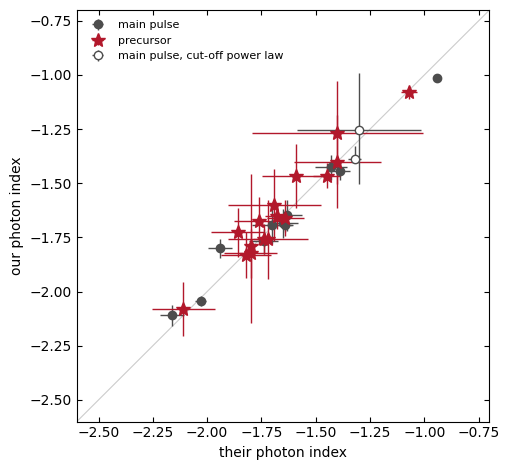

In [3]:
fig, ax = plt.subplots(figsize=(5.2, 4.8))
for kind, marker in (("main", "o"), ("pre", "*")):
    k = m[m.episode.str.startswith(kind) & ~curved]
    ax.errorbar(k.their_alpha, k.our_alpha, xerr=k.their_alpha_minus / 1.645, yerr=[k.our_minus, k.our_plus], fmt=marker, ms=6 if kind == "main" else 10,
                color="0.3" if kind == "main" else "#b2182b", lw=1, capsize=0, label="main pulse" if kind == "main" else "precursor")
k = m[curved]
ax.errorbar(k.their_alpha, k.our_alpha, xerr=k.their_alpha_minus / 1.645, yerr=[k.our_minus, k.our_plus], fmt="o", mfc="white", ms=6, color="0.3",
            lw=1, capsize=0, label="main pulse, cut-off power law")
lim = [-2.6, -0.7]
ax.plot(lim, lim, color="0.8", lw=0.8, zorder=0)
ax.set(xlabel="their photon index", ylabel="our photon index", xlim=lim, ylim=lim)
ax.legend(fontsize=8, frameon=False)
ax.tick_params(which="both", direction="in", top=True, right=True)
fig.tight_layout(); fig.savefig(FIGURES / "30_index_vs_burlon.png", dpi=150); plt.show()

Our indices agree with theirs. Of the 27 windows they fitted from BAT data, 24 are within 1 sigma and 25 within 2. GRB 060714's main pulse,
where their alpha is the cut-off power law's, agrees through ours (alpha -1.25 against -1.30, and E_peak 42 against 41 keV). The two that
don't are bright main pulses. GRB 061007's is -1.02 against -0.94 +- 0.03, 3.4 sigma, a difference of 0.08 against an error that leaves no
room for calibration. GRB 050318's is at 2.0 sigma, and it peaks inside the band (BAT measures E_peak 59 keV), so a power law describes it
less well. BAT measures E_peak in five windows, between 42 and 63 keV, and one of them is a precursor, GRB 060707's (55 keV).

## 1b. Finding the precursors from BAT's light curve alone

For a Swift pipeline the windows shouldn't have to come from a paper. So here our rule (zhu2026, as for GBM in notebook 23) runs on BAT's
mask-weighted 15-150 keV light curve of each burst (`swift_bat.episodes`, Bayesian blocks on the background-subtracted rates, as notebook 27
does for the bursts GBM also saw), over the BAT event data from 30 s before their first window to 30 s after their last. These precursors are
long and faint, so the bins are 256 ms and 1.024 s rather than GBM's tens of ms. Their precursor counts as found when ours overlaps it.

In [4]:
from instruments import swift_bat as B


def our_episodes(name, tres):
    w = theirs[theirs.grb == name].set_index("episode")
    cat = B.catalogue()[name]
    span = (max(cat["events_from"], w.t1_s.min() - 30), min(cat["events_to"], w.t2_s.max() + 30))
    around = w.loc["main", "t1_s"] if w.loc["main", "t1_s"] < cat["events_to"] else w.t1_s.min()
    found, blocks = B.episodes(B.burst(name), tres, 0.0, span, around=around)
    return found["zhu2026"], len(blocks)


rows = []
for name, w in theirs.groupby("grb", sort=True):
    w = w.set_index("episode")
    pres = w[w.index.str.startswith("pre")]
    for tres in (0.256, 1.024):
        row = dict(grb=name, tres_s=tres, their_pre=" ".join(f"{a:g} to {b:g}" for a, b in zip(pres.t1_s, pres.t2_s)),
                   their_main=f"{w.loc['main', 't1_s']:g} to {w.loc['main', 't2_s']:g}")
        try:
            f, nblocks = our_episodes(name, tres)
        except Exception as error:
            rows.append(dict(row, note=f"{type(error).__name__}: {error}"[:120]))
            continue
        row.update(our_pe=f"{f.pe[0]:.1f} to {f.pe[1]:.1f}" if f.pe else "", our_me=f"{f.me[0]:.1f} to {f.me[1]:.1f}" if f.me else "",
                   blocks=nblocks, flags=" ".join(f.flags), pe_start=f.pe[0] if f.pe else np.nan, pe_stop=f.pe[1] if f.pe else np.nan,
                   me_start=f.me[0] if f.me else np.nan, me_stop=f.me[1] if f.me else np.nan)
        row["found"] = bool(f.pe) and any(f.pe[0] < b and a < f.pe[1] for a, b in zip(pres.t1_s, pres.t2_s))
        if row["found"]:
            a, b = min(zip(pres.t1_s, pres.t2_s), key=lambda ab: abs(ab[0] - f.pe[0]))
            row.update(d_start=f.pe[0] - a, d_stop=f.pe[1] - b)
        rows.append(row)
ours_found = pd.DataFrame(rows)
print(ours_found.drop(columns=["pe_start", "pe_stop", "me_start", "me_stop"]).round(2).to_string(index=False))
for tres, g in ours_found.groupby("tres_s"):
    print(f"{tres} s bins: their precursor found in {int(g.found.fillna(False).sum())} of {len(g)} bursts; "
          f"median |start difference| {g.d_start.abs().median():.1f} s, |stop difference| {g.d_stop.abs().median():.1f} s")

       grb  tres_s                        their_pre     their_main           our_pe         our_me  blocks                                                flags  found  d_start  d_stop
 GRB050315    0.26                   -57.5 to -25.5     -6.4 to 52   -56.0 to -47.3   -6.3 to 82.0      12                          emission_reaches_background   True     1.52  -21.78
 GRB050315    1.02                   -57.5 to -25.5     -6.4 to 52   -56.2 to -47.0   -6.1 to 82.0      11                          emission_reaches_background   True     1.26  -21.52
 GRB050318    0.26                      -1.1 to 5.8   22.9 to 29.9      -0.6 to 7.3   23.5 to 31.9      13                          emission_reaches_background   True     0.50    1.54
 GRB050318    1.02                      -1.1 to 5.8   22.9 to 29.9      -0.6 to 7.6   23.0 to 31.1      12                          emission_reaches_background   True     0.50    1.79
 GRB050401    0.26                    -7.28 to 6.71  20.7 to 29.71     -7.7 to -

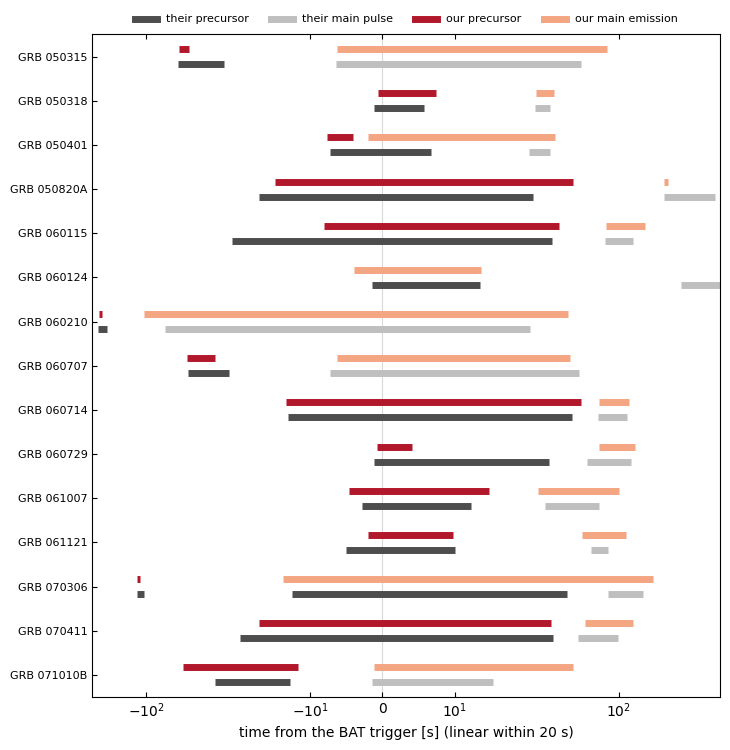

In [5]:
from matplotlib.lines import Line2D

g = ours_found[ours_found.tres_s == 0.256].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.4, 0.42 * len(g) + 1.3))
for i, r in g.iterrows():
    w = theirs[theirs.grb == r.grb].set_index("episode")
    for ep, row in w.iterrows():
        ax.plot([row.t1_s, row.t2_s], [i + 0.17] * 2, color="0.75" if ep == "main" else "0.3", lw=5, solid_capstyle="butt")
    for key, colour in (("pe", "#b2182b"), ("me", "#f4a582")):
        if np.isfinite(r.get(f"{key}_start", np.nan)):
            ax.plot([r[f"{key}_start"], r[f"{key}_stop"]], [i - 0.17] * 2, color=colour, lw=5, solid_capstyle="butt")
ax.set_yticks(range(len(g)), g.grb.str.replace("GRB", "GRB "), fontsize=8)
ax.set_xscale("symlog", linthresh=20)
ax.set(xlim=(-260, 600), ylim=(len(g) - 0.5, -0.5), xlabel="time from the BAT trigger [s] (linear within 20 s)")
ax.axvline(0, color="0.85", lw=0.8, zorder=0)
handles = [Line2D([], [], color=c, lw=5) for c in ("0.3", "0.75", "#b2182b", "#f4a582")]
ax.legend(handles, ["their precursor", "their main pulse", "our precursor", "our main emission"], fontsize=8, frameon=False, ncol=4,
          loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.tick_params(which="both", direction="in", top=True)
fig.tight_layout(); fig.savefig(FIGURES / "30_windows_from_bat.png", dpi=150); plt.show()

From BAT's light curve alone our rule finds their precursor in 14 of the 15 bursts at 256 ms (13 at 1.024 s), and the starts agree to a
median of 1.6 s. Two differ by more than 10 s (GRB 060115 and 071010B). The one it misses, GRB 060124, is the burst whose main pulse comes
after BAT's event data end (302 s), so the rule sees the precursor as the only emission and calls it the main one. The ends differ more (a
median of 6.9 s): in GRB 050315, 060210 and 060729 our precursor stops 17-25 s before theirs, at a quiet stretch our rule counts as the gap.
So the pipeline finds Swift precursors without being told where they are.

The same question as section 2, but on our own windows: each precursor and main emission our rule finds (256 ms bins), fitted with a power
law in BAT's band, so that nothing here comes from their paper.

In [6]:
rows = []
for _, r in ours_found[(ours_found.tres_s == 0.256) & ours_found.found.eq(True) & ours_found.me_start.notna()].iterrows():
    bat, out = B.burst(r.grb), dict(grb=r.grb)
    for key in ("pe", "me"):
        try:
            pl = B.fit(B.spectrum_during_slew(bat, r[f"{key}_start"], r[f"{key}_stop"], f"ours_{key}"), B.power_law, [0.05, -1.5])
            out.update({f"{key}_index": pl["params"][1], f"{key}_err": 0.5 * (pl["errors"][1][0] + pl["errors"][1][1])})
        except Exception as error:
            out[f"{key}_note"] = f"{type(error).__name__}: {error}"[:80]
    rows.append(out)
own = pd.DataFrame(rows)
own["softer_by"] = own.me_index - own.pe_index
own["softer_sigma"] = own.softer_by / np.hypot(own.pe_err, own.me_err)
print(own.round(2).to_string(index=False))
ok = own.dropna(subset=["softer_sigma"])
print(f"on our own windows the precursor is softer than the main emission by more than 2 sigma in {int((ok.softer_sigma > 2).sum())} of {len(ok)} bursts "
      f"and harder in {int((ok.softer_sigma < -2).sum())}; the differences run from {ok.softer_by.min():.2f} to {ok.softer_by.max():.2f}")

       grb  pe_index  pe_err  me_index  me_err  softer_by  softer_sigma
 GRB050315     -1.75    0.20     -2.16    0.05      -0.42         -2.01
 GRB050318     -2.11    0.12     -1.90    0.04       0.22          1.70
 GRB050401     -1.35    0.10     -1.44    0.05      -0.09         -0.77
GRB050820A     -1.75    0.07     -1.17    0.04       0.58          6.75
 GRB060115     -1.87    0.11     -1.62    0.08       0.26          1.96
 GRB060210     -1.56    0.17     -1.44    0.05       0.12          0.70
 GRB060707     -1.47    0.16     -1.72    0.09      -0.26         -1.39
 GRB060714     -1.80    0.11     -2.06    0.05      -0.25         -2.05
 GRB060729     -2.11    0.21     -1.79    0.05       0.32          1.46
 GRB061007     -1.10    0.03     -1.04    0.01       0.06          1.89
 GRB061121     -1.63    0.05     -1.44    0.02       0.19          3.37
 GRB070306     -1.48    0.20     -1.67    0.05      -0.19         -0.95
 GRB070411     -1.60    0.08     -1.69    0.08      -0.09       

## 2. Is the precursor softer than its own main pulse?

Dichiara et al.'s point for GRB 230307A is a precursor far softer than its main emission. In BAT's band the comparison is mostly between
photon indices (a more negative index is softer) and, where BAT measures it, E_peak.

In [7]:
rows = []
for grb, w in ours.groupby("grb"):
    main = w[w.episode == "main"]
    for _, p in w[w.episode.str.startswith("pre")].iterrows():
        row = dict(grb=grb, episode=p.episode, pre_index=p.pl_index, pre_note=p.note)
        if len(main) and pd.notna(main.pl_index.iloc[0]):
            mn = main.iloc[0]
            err = np.hypot(0.5 * (p.pl_minus + p.pl_plus), 0.5 * (mn.pl_minus + mn.pl_plus))
            row.update(main_index=mn.pl_index, softer_by=mn.pl_index - p.pl_index, softer_sigma=(mn.pl_index - p.pl_index) / err,
                       main_Ep=mn.Ep_keV, pre_Ep=p.Ep_keV)
        rows.append(row)
cmp = pd.DataFrame(rows)
print(cmp.round(2).to_string(index=False))
c = cmp.dropna(subset=["softer_sigma"])
print(f"precursor softer than its main pulse by more than 2 sigma: {int((c.softer_sigma > 2).sum())} of {len(c)}; harder by more than 2 sigma: {int((c.softer_sigma < -2).sum())}")

       grb episode  pre_index                                                                    pre_note  main_index  softer_by  softer_sigma  main_Ep  pre_Ep
 GRB050315    pre1      -1.76 E_peak not measured by BAT (its photon index allows a peak inside the band)       -2.11      -0.35         -1.86      NaN     NaN
 GRB050318    pre1      -2.08 E_peak not measured by BAT (its photon index allows a peak inside the band)       -1.80       0.28          2.14    59.45     NaN
 GRB050401    pre1      -1.47 E_peak not measured by BAT (its photon index allows a peak inside the band)       -1.43       0.04          0.50      NaN     NaN
GRB050820A    pre1      -1.76 E_peak not measured by BAT (its photon index allows a peak inside the band)         NaN        NaN           NaN      NaN     NaN
 GRB060115    pre1      -1.83 E_peak not measured by BAT (its photon index allows a peak inside the band)       -1.65       0.18          1.41    62.58     NaN
 GRB060124    pre1      -1.82 E_peak not

What would BAT's band show for the two merger precursors? GRB 211211A was seen by BAT, so its precursor and main emission (the zhu2026
windows, measured the way notebook 27 does) are measured directly, with the index that GBM's fits of the same windows predict when folded
through BAT's response as a check. GRB 230307A wasn't, so I fold its GBM Band fits (notebook 12) through six real BAT responses (GRB
211211A's and four of Burlon et al.'s windows). That covers the precursor, the main emission as a whole (m01-m11, each window weighted by its
flux and duration, with 3-7 s missing, notebook 12), its first bright window (m01) and the two long windows. The spread over the responses
says how much the response matters.

In [8]:
from gdt.core.spectra.functions import Band, Comptonized
from spectral_fit_tools import BandLowBreak
from instruments import bat_compare as C
from zhu import RESULTS as ZHU_RESULTS


def gbm_models(name, label):
    """GBM's fits of one of our zhu2026 windows as shapes BAT's response can fold (as bat_compare.gbm_shapes does for the precursor)."""
    r = pd.read_csv(ZHU_RESULTS / name / "spectra_zhu2026.csv").set_index("label").loc[label]
    fin = lambda *k: all(np.isfinite(float(r.get(x, np.nan))) for x in k)
    m = {}
    if fin("Epeak_cpl", "alpha_cpl"):
        m["Comptonized"] = C._shape(Comptonized(), [1.0, r["Epeak_cpl"], r["alpha_cpl"], 100.0])
    if fin("Epeak_band", "alpha_band", "beta_band"):
        m["Band"] = C._shape(Band(), [1.0, r["Epeak_band"], r["alpha_band"], r["beta_band"], 100.0])
    if fin("Eb", "alpha1_lb", "alpha2_lb", "Epeak_lowbreak", "beta_lb"):
        m["two-break"] = C._shape(BandLowBreak(), [1.0, r["Eb"], r["alpha1_lb"], r["alpha2_lb"], r["Epeak_lowbreak"], r["beta_lb"], 2.0, 100.0])
    return m


specs, rows = {}, []
match = pd.read_csv(C.MATCH).set_index("burst")
record, utc, trigdat, met = C._gbm("211211A")
for label, key in (("PE", "pe"), ("ME", "me")):
    w = record["modes"]["zhu2026"][key]
    bat, offset, _, _ = C._bat_and_offset("211211A", match, utc, trigdat, met, at=0.5 * (w[0] + w[1]))
    spec = B.spectrum_during_slew(bat, w[0] - offset, w[1] - offset, f"merger_{label}")
    specs[f"GRB 211211A {label}"] = spec
    pl = B.fit(spec, B.power_law, [0.05, -1.5])
    predicted = {m: C.expected_index(spec, shape) for m, shape in gbm_models("211211A", label).items()}
    rows.append(dict(window=f"{label} {w[0]:g} to {w[1]:g} s", bat_index=pl["params"][1], bat_minus=pl["errors"][1][0], bat_plus=pl["errors"][1][1],
                     from_gbm_low=min(predicted.values()), from_gbm_high=max(predicted.values())))
grb211211a = pd.DataFrame(rows).set_index("window")
print("GRB 211211A in BAT's band:")
print(grb211211a.round(3).to_string())
d = grb211211a.bat_index.iloc[1] - grb211211a.bat_index.iloc[0]          # positive: the precursor is softer
print(f"precursor softer than the main emission by {d:.2f} +- {np.hypot(grb211211a.bat_minus.iloc[0], grb211211a.bat_plus.iloc[1]):.2f}")

GRB 211211A in BAT's band:
                      bat_index  bat_minus  bat_plus  from_gbm_low  from_gbm_high
window                                                                           
PE -0.016 to 0.408 s     -2.032      0.101     0.098        -1.908         -1.803
ME 1.1 to 12.336 s       -1.252      0.013     0.014        -1.129         -1.084
precursor softer than the main emission by 0.78 +- 0.10


In [9]:
for grb, ep in (("GRB050820A", "pre1"), ("GRB060210", "main"), ("GRB050401", "main"), ("GRB060115", "main")):
    w = theirs.set_index(["grb", "episode"]).loc[(grb, ep)]
    specs[f"{grb} {ep}"] = B.spectrum_during_slew(B.burst(grb), w.t1_s, w.t2_s, f"response_{ep}")
e = pd.read_csv("shared/epeak_230307A.csv", comment="#").set_index("label")
band_of = lambda r: C._shape(Band(), [1.0, r.Epeak_keV, r.alpha, r.beta, 100.0])


def energy_flux(shape):
    return quad(lambda x: np.exp(2 * x) * float(shape(np.array([np.exp(x)]))[0]), np.log(10), np.log(1000), limit=400)[0]


parts = [(band_of(e.loc[m]), (e.loc[m, "t_stop"] - e.loc[m, "t_start"]) * e.loc[m, "flux_10_1000keV_erg_cm2_s"] / energy_flux(band_of(e.loc[m])))
         for m in [f"m{i:02d}" for i in range(1, 12)]]
shapes = {"pre": band_of(e.loc["pre"]), "main as a whole": lambda x: sum(w * s(x) for s, w in parts), "m01 (0.32-3 s)": band_of(e.loc["m01"]),
          "7-18 s": band_of(e.loc["t1_07_18"]), "18-40 s": band_of(e.loc["t1_18_40"])}
grb230307a = pd.DataFrame([{"response": r, **{k: C.expected_index(spec, sh) for k, sh in shapes.items()}} for r, spec in specs.items()]).set_index("response")
print("GRB 230307A folded into BAT's band:")
print(grb230307a.round(3).to_string())
for k in shapes:
    if k != "pre":
        x = grb230307a[k] - grb230307a["pre"]                           # positive: the precursor is softer
        print(f"precursor softer than {k} by {x.mean():.2f} (spread over the responses {x.max() - x.min():.2f})")

GRB 230307A folded into BAT's band:
                   pre  main as a whole  m01 (0.32-3 s)  7-18 s  18-40 s
response                                                                
GRB 211211A PE  -1.163           -1.146          -0.602  -0.985   -1.447
GRB 211211A ME  -1.178           -1.145          -0.603  -0.987   -1.451
GRB050820A pre1 -1.106           -1.146          -0.585  -0.974   -1.437
GRB060210 main  -1.139           -1.146          -0.594  -0.980   -1.443
GRB050401 main  -1.148           -1.146          -0.596  -0.982   -1.445
GRB060115 main  -1.097           -1.147          -0.583  -0.973   -1.436
precursor softer than main as a whole by -0.01 (spread over the responses 0.08)
precursor softer than m01 (0.32-3 s) by 0.54 (spread over the responses 0.06)
precursor softer than 7-18 s by 0.16 (spread over the responses 0.07)
precursor softer than 18-40 s by -0.30 (spread over the responses 0.07)


In BAT's band the precursors look like their main pulses. On their windows the precursor is softer by more than 2 sigma in 2 of 14 bursts
(GRB 050318 and 061121, by 0.28 and 0.26) and harder in 2 (GRB 060714 and 071010B, whose main pulses peak inside the band, at 42 and 48
keV). On our own windows (section 1b) 2 are softer and 3 harder, and every difference lies between -0.42 and +0.58. The largest is GRB
050820A's, against only the first 17 s of a main pulse that BAT's event data cut off. GRB 211211A's precursor, measured the same way, is
softer by 0.78 +- 0.10, more than any of them.

GRB 230307A's wouldn't stand out. Folded through BAT's responses, its precursor and its main emission as a whole give the same index
(-1.14 and -1.15), because the precursor's E_peak (170 keV) lies above the band and the main emission's long soft tail steepens the whole.
Only against its first bright window (0.32-3 s) would it look softer, by 0.54. So none of Burlon et al.'s precursors is soft the way GRB
211211A's is, but BAT's band alone can't tell whether any is soft the way GRB 230307A's is. That needs an E_peak above 150 keV, which only a
wider band (GBM, Konus-Wind) measures. BAT also comes out about 0.15 steeper than GBM's fits predict for both of GRB 211211A's windows,
which cancels in the difference.

## 3. Energy and timescale against the merger precursors

Dichiara et al. read GRB 230307A's precursor as a resonant shattering flare: the tidal energy rate needed is the precursor's luminosity
over an efficiency of 0.2, against about $10^{50}$ erg/s for the fiducial neutron star. Here is the 15-150 keV rest-frame luminosity of
each precursor (a lower bound on the bolometric one) against its rest-frame duration, with the two merger precursors put in the same band
from my fits (notebooks 12 and 14). The precursors' energies come from our power-law fits of their windows (`bat_sample.eiso_rest`,
defined as theirs), because BAT's normalisations here match the BAT catalogue's to a few per cent (notebook 27) while their printed
energies come out lower. Both are listed. The line is the luminosity a flare at the fiducial rate could give.

In [10]:
def band(e, a, b, ep):
    e0 = ep / (2 + a); ec = (a - b) * e0
    return np.where(e < ec, (e / 100) ** a * np.exp(-e / e0), ((a - b) * e0 / 100) ** (a - b) * np.exp(b - a) * (e / 100) ** b)

def cpl(e, a, ep):
    return (e / 100) ** a * np.exp(-e * (2 + a) / ep)

mergers = []
for burst, z, f in (("GRB 230307A", 0.065, "shared/epeak_230307A.csv"), ("GRB 211211A", 0.0762, "shared/epeak_211211A.csv")):
    r = pd.read_csv(f, comment="#").set_index("label").loc["pre"]
    shape = (lambda e, r=r: band(e, r.alpha, r.beta, r.Epeak_keV)) if r.model == "Band" else (lambda e, r=r: cpl(e, r.alpha, r.Epeak_keV))
    energy = lambda lo, hi: quad(lambda x: np.exp(2 * x) * shape(np.exp(x)), np.log(lo), np.log(hi), limit=300)[0]
    k = energy(15 / (1 + z), 150 / (1 + z)) / energy(10, 1000)
    L = 4 * np.pi * Planck18.luminosity_distance(z).to(u.cm).value ** 2 * r.flux_10_1000keV_erg_cm2_s * k
    mergers.append(dict(burst=burst, duration_rest_s=(r.t_stop - r.t_start) / (1 + z), L_15_150=L))
mergers = pd.DataFrame(mergers)
p = theirs[theirs.episode.str.startswith("pre")].merge(ours[["grb", "episode", "eiso_15_150_rest", "eiso_vs_theirs"]], on=["grb", "episode"], how="left")
p["duration_rest_s"] = (p.t2_s - p.t1_s) / (1 + p.z)
p["L_15_150"] = p.eiso_15_150_rest / p.duration_rest_s
p["L_15_150_theirs"] = p.eiso_erg / p.duration_rest_s
p["needed_over_fiducial"] = p.L_15_150 / 0.2 / 1e50
mergers["needed_over_fiducial"] = mergers.L_15_150 / 0.2 / 1e50
print(mergers.round(3).to_string(index=False))
print(p[["grb", "episode", "z", "duration_rest_s", "eiso_15_150_rest", "eiso_erg", "eiso_vs_theirs", "L_15_150", "needed_over_fiducial"]].round(3).to_string(index=False))
v = ours[ours.eiso_vs_theirs.notna()]
print(f"our energies over theirs, every BAT window: median {v.eiso_vs_theirs.median():.2f}, range {v.eiso_vs_theirs.min():.2f}-{v.eiso_vs_theirs.max():.2f} ({len(v)} windows)")
print(f"Burlon et al.'s precursors: rest-frame duration {p.duration_rest_s.min():.1f}-{p.duration_rest_s.max():.1f} s (median {p.duration_rest_s.median():.1f}); "
      f"L(15-150 keV) median {p.L_15_150.median():.1e} erg/s; {p.needed_over_fiducial.min():.1f}-{p.needed_over_fiducial.max():.0f} times the fiducial rate; "
      f"below it: {list(p.grb[p.needed_over_fiducial < 1])}")

      burst  duration_rest_s     L_15_150  needed_over_fiducial
GRB 230307A            0.361 1.683262e+50                 8.416
GRB 211211A            0.416 1.462558e+49                 0.731
       grb episode     z  duration_rest_s  eiso_15_150_rest     eiso_erg  eiso_vs_theirs     L_15_150  needed_over_fiducial
GRB050820A    pre1 2.600           10.833      1.214082e+52 1.140000e+52           1.065 1.120691e+51                56.035
 GRB060124    pre1 2.297            4.550      4.988903e+51 4.570000e+51           1.092 1.096561e+51                54.828
 GRB061121    pre1 1.314            6.482      2.389655e+51 1.370000e+51           1.744 3.686441e+50                18.432
GRB071010B    pre1 0.947            8.850      7.276613e+50 7.210000e+51           0.101 8.222615e+49                 4.111
 GRB070411    pre1 2.954           12.898      1.354432e+52 1.280000e+52           1.058 1.050083e+51                52.504
 GRB070306    pre1 1.490            6.024      1.056737e+51 3.77

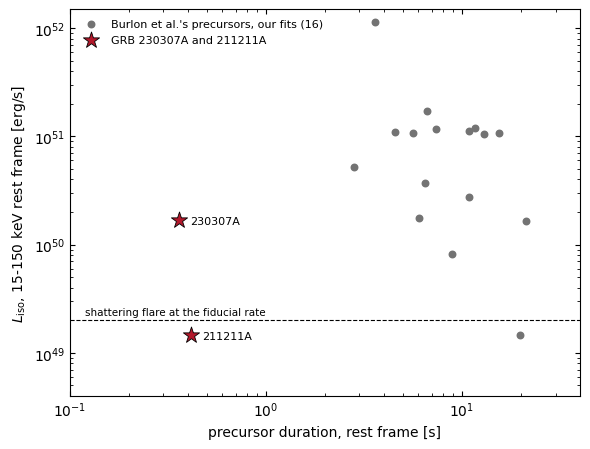

In [11]:
fig, ax = plt.subplots(figsize=(6.0, 4.6))
ax.scatter(p.duration_rest_s, p.L_15_150, s=22, color="0.45", label=f"Burlon et al.'s precursors, our fits ({int(p.L_15_150.notna().sum())})")
ax.scatter(mergers.duration_rest_s, mergers.L_15_150, s=150, marker="*", color="#b2182b", edgecolor="k", lw=0.6, zorder=3, label="GRB 230307A and 211211A")
for _, r in mergers.iterrows():
    ax.annotate(r.burst.replace("GRB ", ""), (r.duration_rest_s, r.L_15_150), textcoords="offset points", xytext=(8, -3), fontsize=8)
ax.axhline(0.2 * 1e50, color="k", ls="--", lw=0.8)
ax.annotate("shattering flare at the fiducial rate", (0.12, 0.2e50), textcoords="offset points", xytext=(0, 4), fontsize=7.5)
ax.set(xscale="log", yscale="log", xlabel="precursor duration, rest frame [s]", ylabel=r"$L_{\rm iso}$, 15-150 keV rest frame [erg/s]", xlim=(0.1, 40),
       ylim=(4e48, 1.5e52))
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.tick_params(which="both", direction="in", top=True, right=True)
fig.tight_layout(); fig.savefig(FIGURES / "30_precursor_power.png", dpi=150); plt.show()

Their search could only find precursors bright enough at their redshifts (0.54-3.91). In data limited by the background, a pulse's
significance goes roughly as its mean flux times the square root of its duration, so the faintest precursor they found sets a floor, and a
precursor like either merger's can be moved out in redshift until it reaches that floor. Both are compared in the observed band that is
15-150 keV in the rest frame, so this is an estimate to a factor of about 2, not a detection threshold.

In [12]:
dl = Planck18.luminosity_distance(p.z.values).to(u.cm).value
p["F"] = p.L_15_150 / (4 * np.pi * dl ** 2)          # mean flux in the observed band that is 15-150 keV in the rest frame
p["F_sqrtT"] = p.F * np.sqrt(p.t2_s - p.t1_s)
faintest = p.loc[p.F_sqrtT.idxmin()]
zs = np.linspace(0.005, 6, 12000)
DL = Planck18.luminosity_distance(zs).to(u.cm).value
for _, r in mergers.iterrows():
    reach = r.L_15_150 / (4 * np.pi * DL ** 2) * np.sqrt(r.duration_rest_s * (1 + zs))
    print(f"{r.burst}: as significant as their faintest precursor ({faintest.grb} {faintest.episode}, z = {faintest.z}) out to z = {zs[reach >= faintest.F_sqrtT].max():.2f}")
bursts = p.drop_duplicates("grb")
print(f"their bursts below z = 1: {int((bursts.z < 1).sum())} of {len(bursts)}; median z {bursts.z.median():.2f}")

GRB 230307A: as significant as their faintest precursor (GRB070306 pre1, z = 1.49) out to z = 0.77
GRB 211211A: as significant as their faintest precursor (GRB070306 pre1, z = 1.49) out to z = 0.26
their bursts below z = 1: 2 of 15; median z 2.30


Burlon et al.'s precursors aren't like the two merger precursors. They last 2.8-21.3 s in their rest frames (a median of 8.1 s), against
0.36 and 0.42 s, and their 15-150 keV luminosities (a median of 1.1e51 erg/s, a lower bound on the bolometric one) would need 0.7 to 570
times the tidal energy rate a shattering flare can draw at the fiducial values. Only GRB 060729's, at z = 0.54, needs less. In the same band
GRB 211211A's precursor needs 0.73 times it and GRB 230307A's 8.4 times. The GBM precursors with a redshift in Zhu et al.'s sample span a
similar range, 0.16 to 770 times (notebook 25, bolometric), so the energy budget doesn't separate the classes.

Our energies of their windows are a median 1.26 times their printed ones (0.74-2.8 over 26 windows). The two left out are off by almost
exactly a factor of 10, with the same leading digits (GRB 070411's main pulse, 1.41e51 against our 1.56e52, and GRB 071010B's precursor,
7.21e51 against 7.28e50), which looks like a misprint in their table.

The comparison is also biased. Their search could only find a precursor like GRB 230307A's out to z = 0.8, and one like GRB 211211A's out
to z = 0.3, and only one of their 15 bursts (GRB 060729, z = 0.54) is that near. So the Swift sample shows that long, luminous precursors
are common in distant long bursts, but it can't say whether short, faint ones like the mergers' are rare among them.